# Leverage points

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from statsmodels.api import OLS
from statsmodels.stats.outliers_influence import OLSInfluence
from ipywidgets import interact, FloatSlider

The leverage $h_{ii}$ of an observation is the $i$-th element of the diagonal of the hat matrix $H = X(X^TX)^{-1}X^T$. Since $\hat y = Hy$, it measures how much $y_i$ weighs in its own fitted value. In simple regression,
$$h_{ii} = \frac{1}{n} + \frac{D_M^2(x_i)}{n-1},$$
where $D_M$ is the Mahalanobis distance of $x_i$ to $\bar x$: the observations far from the center of the covariates are the ones with high leverage.

In [2]:
beta_0 = 1
beta_1 = 1.5

def simulate(n_regular, seed=111):
    # n_regular points equally spaced in [0, 5], and one more point far away, at x = 6
    rng = np.random.default_rng(seed)
    x = np.append(np.linspace(0, 5, n_regular), [6])
    Y = beta_0 + beta_1*x + rng.normal(0, 0.5, len(x))
    return x, Y

## Two ways of computing the leverage

In [3]:
x, Y = simulate(20)
n = len(x)

# With the Mahalanobis distance
S = x.var(ddof=1)
D_M_2 = (x-x.mean())**2/S
h_ii = 1/n + D_M_2/(n-1)
h_ii

array([0.17082067, 0.14770437, 0.12698768, 0.10867061, 0.09275316,
       0.07923532, 0.0681171 , 0.0593985 , 0.05307951, 0.04916013,
       0.04764038, 0.04852024, 0.05179971, 0.0574788 , 0.06555751,
       0.07603583, 0.08891377, 0.10419133, 0.1218685 , 0.14194529,
       0.24012158])

In [4]:
# With the hat matrix
X = np.vstack([np.ones(n), x]).T
p = X.shape[1]
h_ii = np.diag(X @ np.linalg.solve(X.T @ X, X.T))
h_ii

array([0.17082067, 0.14770437, 0.12698768, 0.10867061, 0.09275316,
       0.07923532, 0.0681171 , 0.0593985 , 0.05307951, 0.04916013,
       0.04764038, 0.04852024, 0.05179971, 0.0574788 , 0.06555751,
       0.07603583, 0.08891377, 0.10419133, 0.1218685 , 0.14194529,
       0.24012158])

And with `statsmodels`

In [5]:
np.max(np.abs(OLSInfluence(OLS(Y, X).fit()).hat_matrix_diag - h_ii))

np.float64(1.3877787807814457e-16)

In [6]:
def plot_leverage(ax, x, Y):
    n = len(x)
    X = np.vstack([np.ones(n), x]).T
    h_ii = np.diag(X @ np.linalg.solve(X.T @ X, X.T))
    beta = np.linalg.lstsq(X, Y, rcond=None)[0]
    x_grid = np.array([-0.3, 6.3])

    ax.plot(x_grid, beta[0] + beta[1]*x_grid, color='#1f4e79', lw=2, label='Fitted line')
    sc = ax.scatter(x, Y, c=h_ii, cmap='Reds', vmin=0, vmax=0.8, s=40 + 500*h_ii,
                    edgecolor='#7a0c14', linewidth=0.8, zorder=3, label='Observed data (size and color: leverage)')
    ax.set_xlabel('x')
    ax.set_title(f'{n} points\nfar point $h_{{ii}}$ = {h_ii[-1]:.2f}, threshold $2p/n$ = {4/n:.2f}')
    ax.grid(True, alpha=0.25)
    return sc

## The fewer the points, the higher the leverage of the far one

The sum of the leverages is always $p$ (here 2), so with fewer observations each one has more. The last point, at $x = 6$, is always the one with the highest leverage.

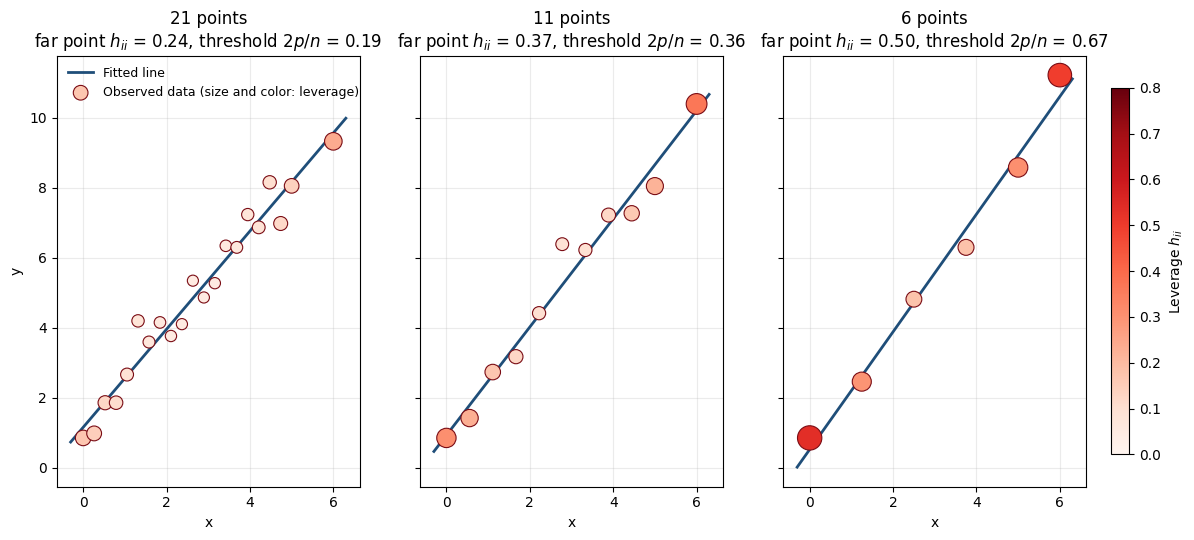

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), sharey=True)
for ax, n_regular in zip(axes, [20, 10, 5]):
    sc = plot_leverage(ax, *simulate(n_regular))
axes[0].set_ylabel('y')
axes[0].legend(loc='upper left', frameon=False, fontsize=9)
fig.colorbar(sc, ax=axes, label='Leverage $h_{ii}$', shrink=0.85, pad=0.02)

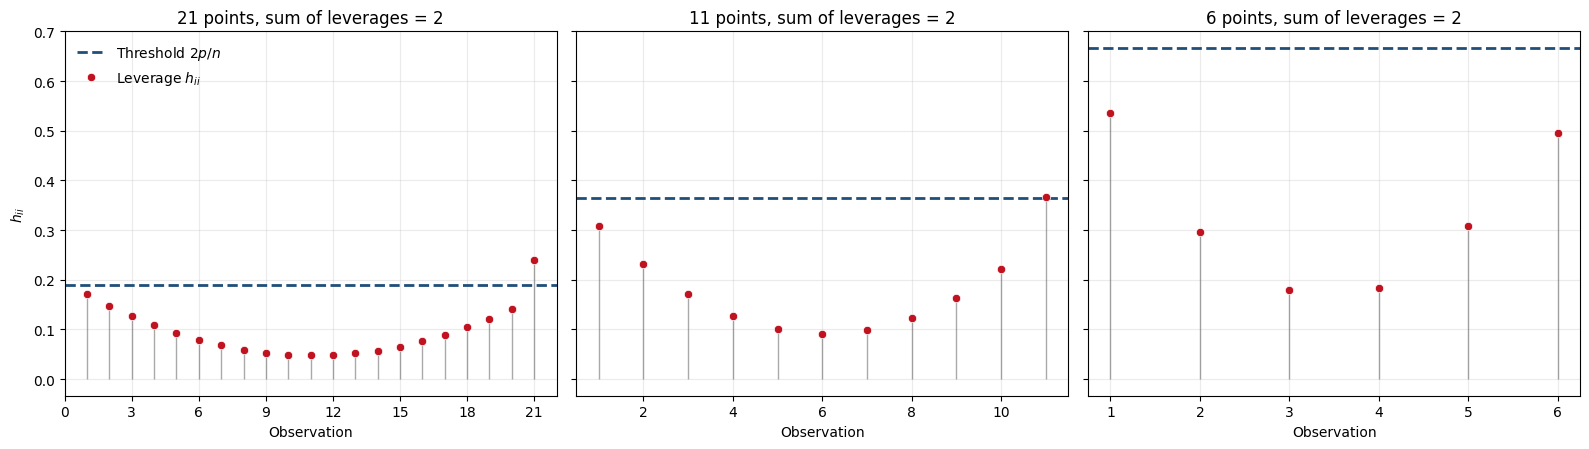

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, n_regular in zip(axes, [20, 10, 5]):
    x, Y = simulate(n_regular)
    n = len(x)
    X = np.vstack([np.ones(n), x]).T
    h_ii = np.diag(X @ np.linalg.solve(X.T @ X, X.T))
    idx = np.arange(1, n+1)

    ax.vlines(idx, 0, h_ii, color='#555555', lw=1, alpha=0.5)
    ax.axhline(2*p/n, ls='--', color='#1f4e79', lw=2, label='Threshold $2p/n$')
    ax.plot(idx, h_ii, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5,
            label='Leverage $h_{ii}$')
    ax.set_xlabel('Observation')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(f'{n} points, sum of leverages = {h_ii.sum():.0f}')
    ax.grid(True, alpha=0.25)
axes[0].set_ylabel('$h_{ii}$')
axes[0].legend(loc='upper left', frameon=False)
plt.tight_layout()

## Leverage is not influence

A point with high leverage *can* change the fitted line a lot, but it only does it if its response is far from what the rest of the data predict. Move the last point with the sliders (this cell needs a running kernel).

In [9]:
x, Y = simulate(10)

def plot_moved_point(ax, x_new, shift):
    # Move the last point to x_new, and shift its response away from the true line
    x_mod, Y_mod = x.copy(), Y.copy()
    x_mod[-1] = x_new
    Y_mod[-1] = beta_0 + beta_1*x_new + shift

    X_mod = np.vstack([np.ones(len(x_mod)), x_mod]).T
    h_new = np.diag(X_mod @ np.linalg.solve(X_mod.T @ X_mod, X_mod.T))[-1]
    beta_with = np.linalg.lstsq(X_mod, Y_mod, rcond=None)[0]
    beta_without = np.linalg.lstsq(X_mod[:-1], Y_mod[:-1], rcond=None)[0]
    x_grid = np.array([-0.5, 10.5])

    ax.plot(x_grid, beta_without[0] + beta_without[1]*x_grid, '--', color='#555555', lw=1.5,
            label='Fitted line without the point')
    ax.plot(x_grid, beta_with[0] + beta_with[1]*x_grid, color='#1f4e79', lw=2, label='Fitted line with the point')
    ax.plot(x_mod[:-1], Y_mod[:-1], 'o', color='#c1121f', markersize=6, markeredgecolor='white',
            markeredgewidth=0.5, label='Observed data')
    ax.plot(x_mod[-1], Y_mod[-1], 'o', color='#c1121f', markersize=13, markeredgecolor='#333333',
            markeredgewidth=1.5, label='Moved point')
    ax.set_xlim(-0.5, 10.5)
    ax.set_ylim(-4, 22)
    ax.set_xlabel('x')
    ax.set_title(f'$h_{{ii}}$ = {h_new:.2f}, slope {beta_without[1]:.2f} $\\to$ {beta_with[1]:.2f}')
    ax.grid(True, alpha=0.25)

def interactive_point(x_new, shift):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    plot_moved_point(ax, x_new, shift)
    ax.set_ylabel('y')
    ax.legend(loc='upper left', frameon=False)
    plt.show()

interact(interactive_point,
         x_new=FloatSlider(value=6, min=0, max=10, step=0.5, description='x'),
         shift=FloatSlider(value=0, min=-6, max=6, step=0.5, description='shift in y'));

interactive(children=(FloatSlider(value=6.0, description='x', max=10.0, step=0.5), FloatSlider(value=0.0, desc…

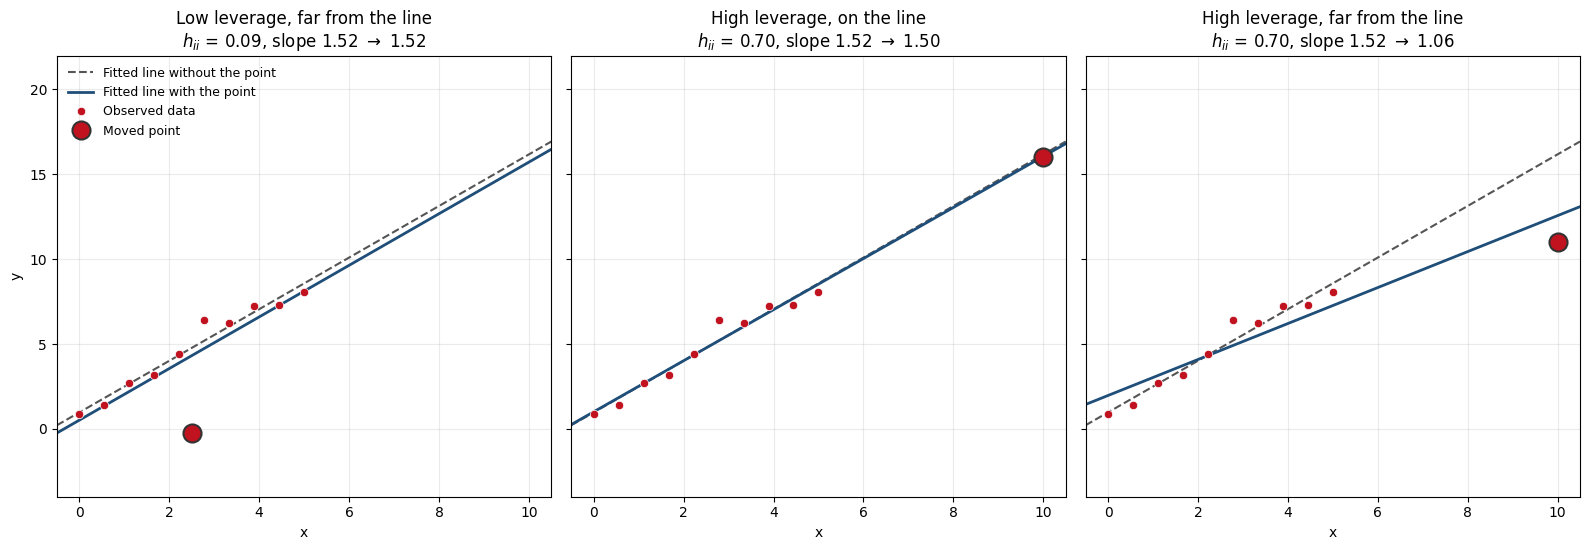

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), sharey=True)
cases = [(2.5, -5, 'Low leverage, far from the line'),
         (10, 0, 'High leverage, on the line'),
         (10, -5, 'High leverage, far from the line')]
for ax, (x_new, shift, name) in zip(axes, cases):
    plot_moved_point(ax, x_new, shift)
    ax.set_title(name + '\n' + ax.get_title())
axes[0].set_ylabel('y')
axes[0].legend(loc='upper left', frameon=False, fontsize=9)
plt.tight_layout()